In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

df = pd.read_csv('../data/cleaned_ecommerce_sales.csv')

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (1005, 11)


,order_id,order_date,customer_id,product_name,category,quantity,price,discount,region,payment_method,status
0,ORD10001,2025-02-01,CUST1175,Vacuum Cleaner,Home & Kitchen,3,13778.0,0.20,South,UPI,Returned
1,ORD10002,2025-11-03,CUST1113,Vacuum Cleaner,Home & Kitchen,3,20722.0,0.00,East,Credit Card,Cancelled
2,ORD10003,2025-06-14,CUST1057,Jacket,Clothing,3,6079.0,0.10,North,Debit Card,Delivered
3,ORD10004,2025-09-13,CUST1089,Microwave,Home & Kitchen,1,13580.0,0.15,North,Cash on Delivery,Cancelled
4,ORD10005,2025-07-01,CUST1011,Vacuum Cleaner,Home & Kitchen,2,8892.0,0.10,East,UPI,Delivered


In [46]:
# Missing values
print("Missing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Data types
print("\nData Types:")
print(df.dtypes) 


Missing Values:
order_id          0
order_date        0
customer_id       8
product_name      0
category          0
quantity          0
price             0
discount          6
region            5
payment_method    4
status            0
dtype: int64

Duplicate Rows: 5

Data Types:
order_id              str
order_date            str
customer_id           str
product_name          str
category              str
quantity            int64
price             float64
discount          float64
region                str
payment_method        str
status                str
dtype: object


In [47]:
df.describe()

,quantity,price,discount
count,1005.000000,1005.000000,999.000000
mean,2.933333,12140.163184,0.096647
std,1.385947,17372.395605,0.069864
min,1.000000,175.000000,0.000000
25%,2.000000,1918.000000,0.050000
50%,3.000000,5736.000000,0.100000
75%,4.000000,13778.000000,0.150000
max,5.000000,88530.000000,0.200000


In [48]:
# Handle categorical missing values

categorical_columns = [
    'customer_id',
    'region',
    'payment_method'
]

for col in categorical_columns:
    df[col] = df[col].fillna('Unknown')

print(df[categorical_columns].isnull().sum())

customer_id       0
region            0
payment_method    0
dtype: int64


In [49]:
# Handle missing discount values

df['discount'] = df['discount'].fillna(
    df['discount'].median()
)

print("Missing discount:", df['discount'].isnull().sum())

Missing discount: 0


In [50]:
print("Remaining Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Remaining Missing Values:
order_id          0
order_date        0
customer_id       0
product_name      0
category          0
quantity          0
price             0
discount          0
region            0
payment_method    0
status            0
dtype: int64

Total Missing Values: 0


In [51]:
# Duplicate Removal and Validation 

# Check duplicate rows

print("Duplicate Rows:", df.duplicated().sum())

# Check duplicate order IDs

print("Duplicate Order IDs:", df['order_id'].duplicated().sum())

Duplicate Rows: 5
Duplicate Order IDs: 5


In [52]:
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Dataset Shape After Removing Duplicates: (1000, 11)


In [53]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Order IDs:", df['order_id'].duplicated().sum())

Duplicate Rows: 0
Duplicate Order IDs: 0


In [54]:
# Data Type Correction 

df['order_date'] = pd.to_datetime(df['order_date'])

print(df['order_date'].dtype) 


datetime64[us]


In [55]:
numeric_columns = [
    'quantity',
    'price',
    'discount'
]

print(df[numeric_columns].dtypes)

quantity      int64
price       float64
discount    float64
dtype: object


In [56]:
df['quantity'] = pd.to_numeric(df['quantity'])
df['price'] = pd.to_numeric(df['price'])
df['discount'] = pd.to_numeric(df['discount']) 



In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        1000 non-null   str           
 1   order_date      1000 non-null   datetime64[us]
 2   customer_id     1000 non-null   str           
 3   product_name    1000 non-null   str           
 4   category        1000 non-null   str           
 5   quantity        1000 non-null   int64         
 6   price           1000 non-null   float64       
 7   discount        1000 non-null   float64       
 8   region          1000 non-null   str           
 9   payment_method  1000 non-null   str           
 10  status          1000 non-null   str           
dtypes: datetime64[us](1), float64(2), int64(1), str(7)
memory usage: 86.1 KB



Column: quantity
Lower Limit: -1.0
Upper Limit: 7.0
Outlier Count: 0

Column: price
Lower Limit: -15876.125
Upper Limit: 31576.875
Outlier Count: 99

Column: discount
Lower Limit: -0.09999999999999999
Upper Limit: 0.3
Outlier Count: 0


<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

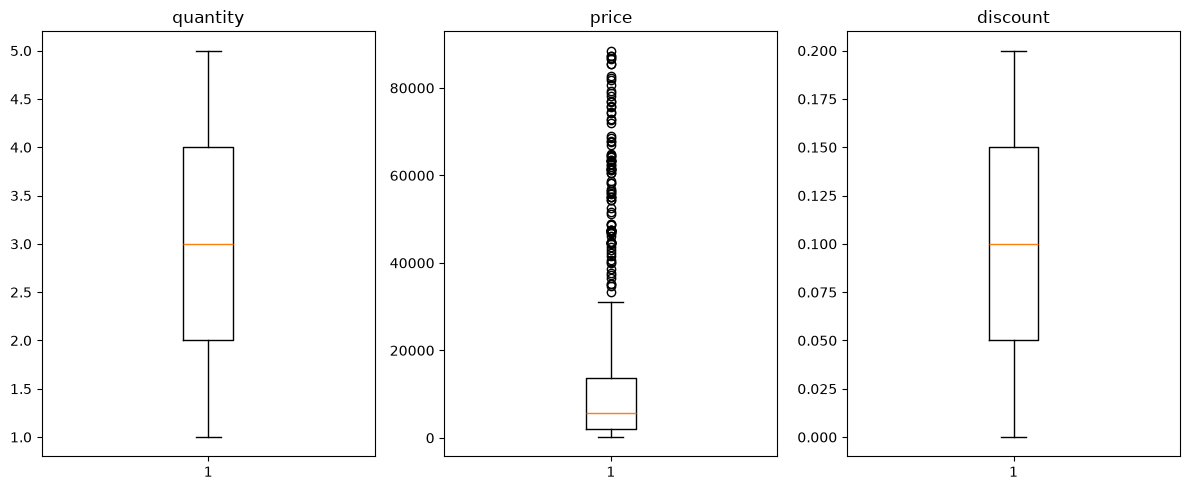

In [58]:
# Outlier Detection using IQR 

numeric_columns = ['quantity', 'price', 'discount']

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"\nColumn: {col}")
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Outlier Count:", len(outliers)) 

    plt.figure(figsize=(12, 5))

for i, col in enumerate(numeric_columns, 1):

    plt.subplot(1, 3, i)
    plt.boxplot(df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [59]:
# Feature Engineering 

df['total_sales'] = (
    df['quantity'] * df['price']
)

print(df[['quantity', 'price', 'total_sales']].head())

   quantity    price  total_sales
0         3  13778.0      41334.0
1         3  20722.0      62166.0
2         3   6079.0      18237.0
3         1  13580.0      13580.0
4         2   8892.0      17784.0


In [60]:
df['discount_amount'] = (
    df['total_sales'] * df['discount']
)

print(df[['total_sales', 'discount_amount']].head())

   total_sales  discount_amount
0      41334.0           8266.8
1      62166.0              0.0
2      18237.0           1823.7
3      13580.0           2037.0
4      17784.0           1778.4


In [61]:
df['net_revenue'] = (
    df['total_sales'] - df['discount_amount']
)

print(df[['total_sales', 'discount_amount', 'net_revenue']].head())

   total_sales  discount_amount  net_revenue
0      41334.0           8266.8      33067.2
1      62166.0              0.0      62166.0
2      18237.0           1823.7      16413.3
3      13580.0           2037.0      11543.0
4      17784.0           1778.4      16005.6


In [62]:
# Date Feature Engineering 

df['year'] = df['order_date'].dt.year

df['month'] = df['order_date'].dt.month

df['day'] = df['order_date'].dt.day

df['day_name'] = df['order_date'].dt.day_name()

print(df[['order_date', 'year', 'month',
          'day', 'day_name']].head())

  order_date  year  month  day  day_name
0 2025-02-01  2025      2    1  Saturday
1 2025-11-03  2025     11    3    Monday
2 2025-06-14  2025      6   14  Saturday
3 2025-09-13  2025      9   13  Saturday
4 2025-07-01  2025      7    1   Tuesday


In [63]:
df['month_year'] = (
    df['order_date'].dt.to_period('M')
)

print(df[['order_date', 'month_year']].head())

  order_date month_year
0 2025-02-01    2025-02
1 2025-11-03    2025-11
2 2025-06-14    2025-06
3 2025-09-13    2025-09
4 2025-07-01    2025-07


In [ ]:
weekday_orders = df['day_name'].value_counts()

print(weekday_orders) 

# Business insights:
# - Wednesday has the highest order volume (163).
# - Saturday has the lowest order volume (121).
# - Wednesday has 42 more orders than Saturday.

day_name
Wednesday    163
Monday       152
Friday       146
Thursday     142
Tuesday      140
Sunday       136
Saturday     121
Name: count, dtype: int64


In [65]:
# Final Dataset Validation 

# Final dataset validation

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nRevenue Summary:")
print(df[['total_sales',
          'discount_amount',
          'net_revenue']].describe())

Dataset Shape: (1000, 19)

Missing Values:
0

Duplicate Rows:
0

Data Types:
order_id                      str
order_date         datetime64[us]
customer_id                   str
product_name                  str
category                      str
quantity                    int64
price                     float64
discount                  float64
region                        str
payment_method                str
status                        str
total_sales               float64
discount_amount           float64
net_revenue               float64
year                        int32
month                       int32
day                         int32
day_name                      str
month_year              period[M]
dtype: object

Revenue Summary:
         total_sales  discount_amount    net_revenue
count    1000.000000      1000.000000    1000.000000
mean    36588.645000      3339.707500   33248.937500
std     61552.751222      7214.695343   56640.707242
min       220.000000         0.00

In [66]:
# Export processed dataset 

df.to_csv(
    '../data/final_processed_ecommerce.csv',
    index=False
)

print("Final dataset exported successfully!")

Final dataset exported successfully!
